## Task 1: Setting the Baseline

In ML, it is essential to establish a baseline model for comparison with any developments.

### Task 1.1 Data Preparation and Validation Pipeline

- First, explore the training data for any anomalies and visualize some trajectories. Each trajectory consists of 258 lines, one per data point. Note that after a collision, all lines of that trajectory will be zero up to the 258th data point for that trajectory.

Necessary imports

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample

Load dataset from CSV file and analyze it in terms of missing values and dataset summary

In [2]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help

print(df.isnull().sum())
print(df.describe())
df.head()

t      0
x_1    0
y_1    0
x_2    0
y_2    0
x_3    0
y_3    0
Id     0
dtype: int64
                  t           x_1           y_1           x_2           y_2  \
count  1.285000e+06  1.285000e+06  1.285000e+06  1.285000e+06  1.285000e+06   
mean   4.145262e+00 -2.812879e-01 -1.095159e-01  7.171403e-03 -8.201144e-02   
std    3.209813e+00  1.695764e+00  1.167686e+00  1.062984e+00  1.038606e+00   
min    0.000000e+00 -3.082300e+01 -1.785773e+01 -3.083340e+01 -5.245081e+01   
25%    1.054690e+00 -4.118489e-01 -3.928434e-01 -3.295574e-01 -1.918623e-01   
50%    3.945310e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00   
75%    6.953120e+00  5.008268e-01  2.634242e-01  2.103091e-01  2.683916e-01   
max    1.000000e+01  1.634061e+01  2.627623e+01  1.550696e+01  3.567946e+01   

                x_3           y_3            Id  
count  1.285000e+06  1.285000e+06  1.285000e+06  
mean   2.741165e-01  1.915273e-01  6.424995e+05  
std    1.443411e+00  1.683294e+00  3.709477e+05  
min

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


Dataframe should have the data grouped by scenarios

In [3]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
SUBFRAME_SIZE = 257

def fixed_size_subframes(data, n):
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]

Visualize trajectories

2


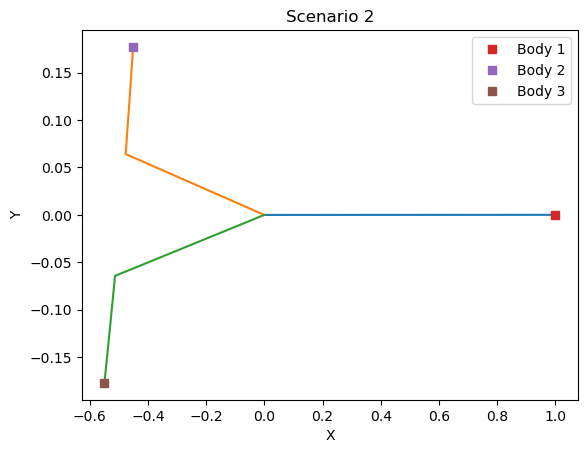

5


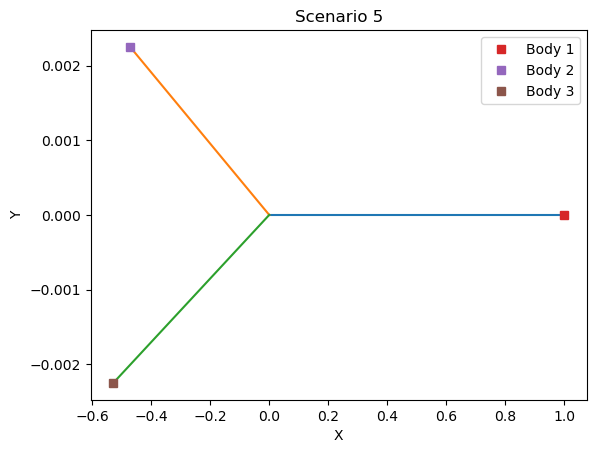

284


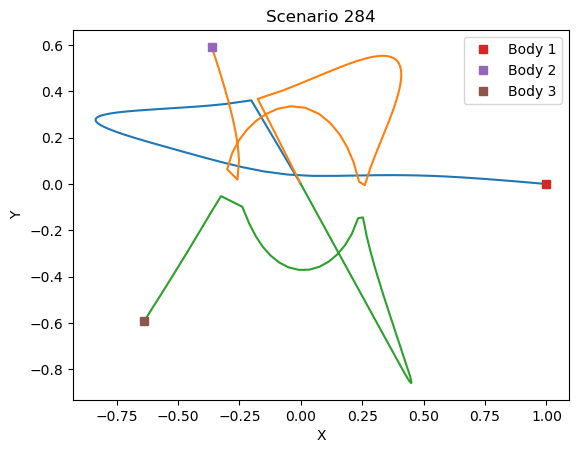

315


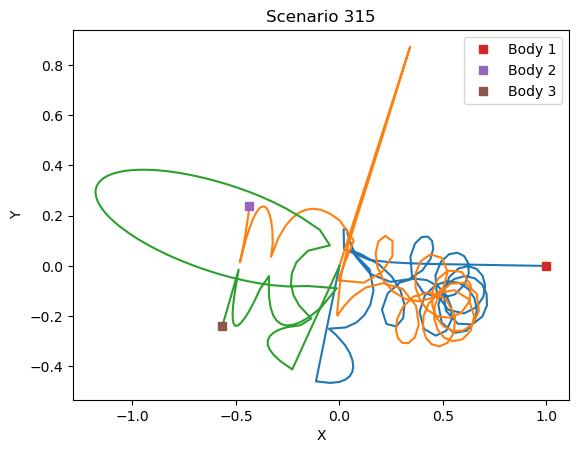

317


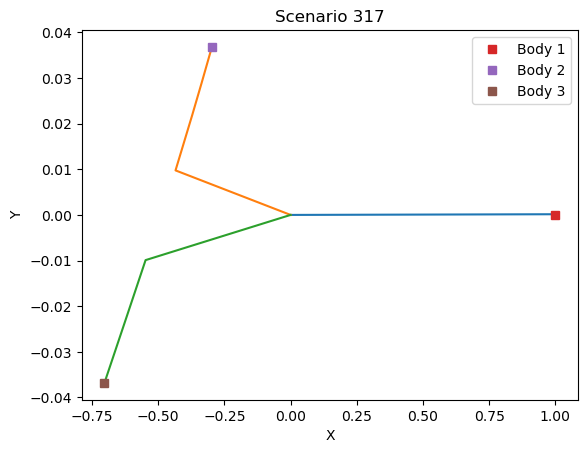

338


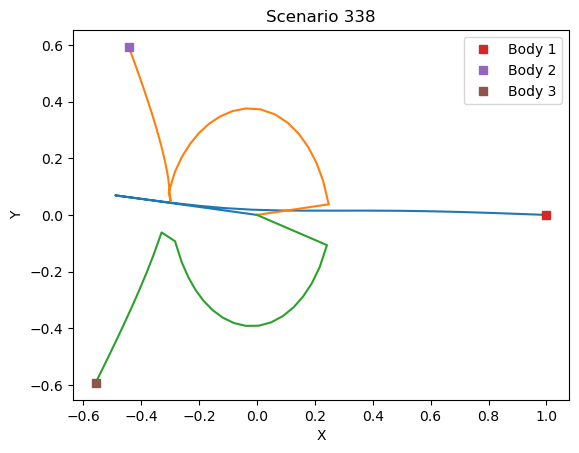

4643


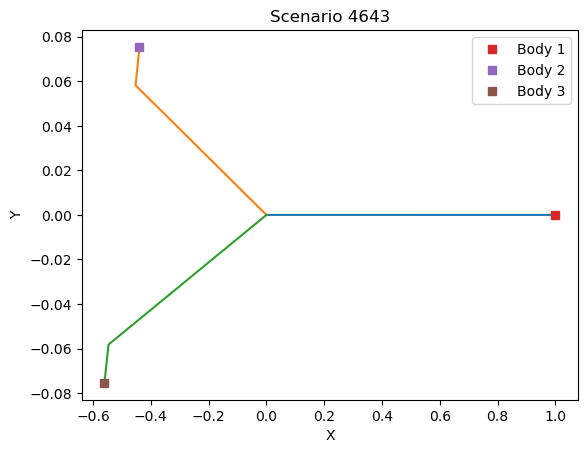

In [4]:
subframes = fixed_size_subframes(df, SUBFRAME_SIZE)

# k = np.random.randint(len(subframes))

ks = [2, 5, 284, 315, 317, 338, 4643] # some scenarios with collisions

# ks = range(10)

for k in ks:
    subframe = subframes[k]
    first_row = subframe.iloc[0]
    
    print(k)
    plt.figure()

    plt.plot(subframe.x_1, subframe.y_1)
    plt.plot(subframe.x_2, subframe.y_2)
    plt.plot(subframe.x_3, subframe.y_3)

    plt.plot(first_row.x_1, first_row.y_1, 's', label='Body 1')
    plt.plot(first_row.x_2, first_row.y_2, 's', label='Body 2')
    plt.plot(first_row.x_3, first_row.y_3, 's', label='Body 3')
    
    plt.legend()
    plt.title(f'Scenario {k}')
    plt.xlabel('X')
    plt.ylabel('Y')
    
    plt.show()

Create features and target matrices from the grouped data

In [5]:
def create_features_and_targets(subframes):
    X_list = []
    y_list = []
    
    for df in subframes:
        initial_conditions = df.iloc[0][['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']].values
        
        for i, row in df.iterrows():
            features = [row['t']] + initial_conditions.tolist()
            X_list.append(features)
            
            targets = row[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']].values
            y_list.append(targets)

    X = pd.DataFrame(X_list, columns=['t', 'x0_1', 'y0_1', 'x0_2', 'y0_2', 'x0_3', 'y0_3'])
    y = pd.DataFrame(y_list, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])
    
    return X, y


X, y = create_features_and_targets(subframes)

Features and target matrices should have information grouped by scenario

In [6]:
X_chunks = fixed_size_subframes(X, SUBFRAME_SIZE)
y_chunks = fixed_size_subframes(y, SUBFRAME_SIZE)

print(X_chunks[0].head())
print(y_chunks[0].head())

          t  x0_1  y0_1      x0_2      y0_2      x0_3      y0_3
0  0.000000   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
1  0.039062   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
2  0.078125   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
3  0.117188   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
4  0.156250   1.0   0.0 -0.266467  0.859196 -0.733533 -0.859196
        x_1       y_1       x_2       y_2       x_3       y_3
0  1.000000  0.000000 -0.266467  0.859196 -0.733533 -0.859196
1  0.999548  0.000092 -0.266261  0.858781 -0.733287 -0.858874
2  0.998190  0.000370 -0.265641  0.857535 -0.732549 -0.857905
3  0.995925  0.000833 -0.264606  0.855456 -0.731318 -0.856289
4  0.992747  0.001483 -0.263154  0.852540 -0.729592 -0.854022


Split dataset into training (80%), validation (10%) and test (10%) sets.

In [7]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

                t  x0_1  y0_1      x0_2      y0_2      x0_3      y0_3
1086339  0.000000   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086340  0.039062   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086341  0.078125   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086342  0.117188   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
1086343  0.156250   1.0   0.0 -0.141885  0.949936 -0.858115 -0.949936
              x_1       y_1       x_2       y_2       x_3       y_3
1086339  1.000000  0.000000 -0.141885  0.949936 -0.858115 -0.949936
1086340  0.999578  0.000141 -0.141685  0.949542 -0.857894 -0.949683
1086341  0.998312  0.000566 -0.141082  0.948358 -0.857229 -0.948924
1086342  0.996198  0.001275 -0.140077  0.946383 -0.856121 -0.947658
1086343  0.993234  0.002270 -0.138666  0.943612 -0.854568 -0.945883


Concatenate the list of DataFrames into single DataFrames for X and y

In [8]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

## Task 1.2 Learn the baseline model


Linear regression model

In [9]:
degree=1

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

Plot the y-y hat and present the RMSE in the validation set

In [9]:
def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()

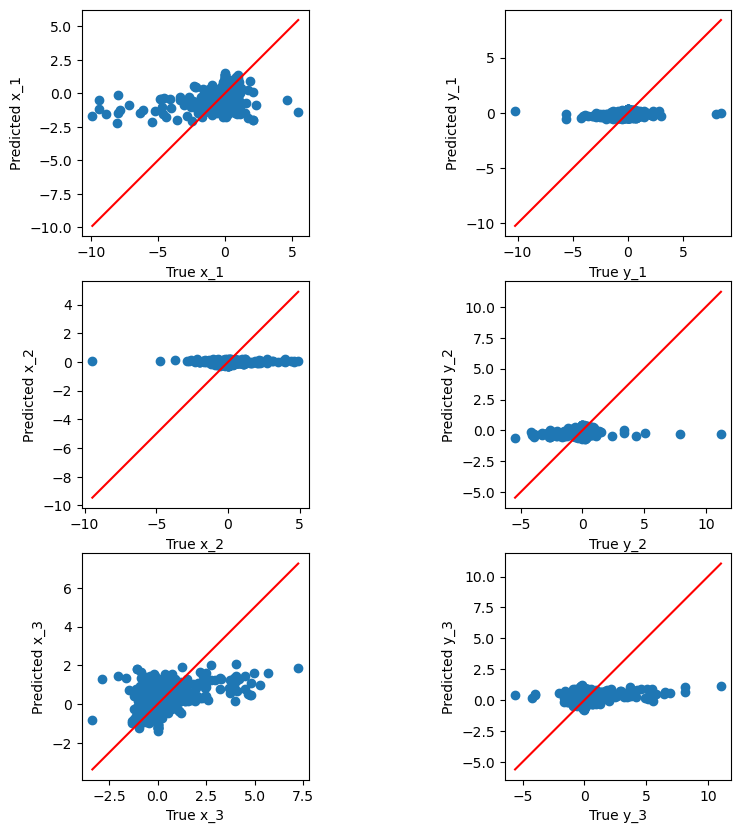

Validation RMSE: 1.3345699794722141


In [10]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = np.sqrt(mean_squared_error(y_dev_df, y_dev_pred))

print(f"Validation RMSE: {rmse}")

RMSE on the test set

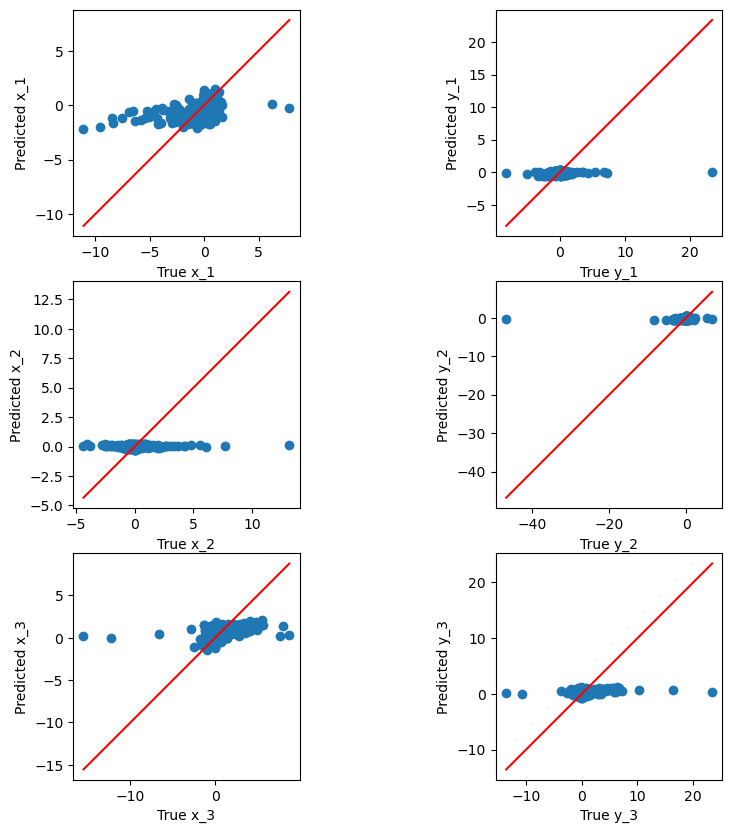

Test RMSE: 1.4425975556989512


In [40]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = np.sqrt(mean_squared_error(y_test_df, y_test_pred))

print(f"Test RMSE: {rmse}")

Dataframe containing X_tests' info for submissions. Function to save model output into csv file ready for submission

In [10]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

def prediction_to_submission(prediction, path):
    predictions_df = pd.DataFrame(prediction, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

    predictions_df['Id'] = range(len(prediction))

    predictions_df = predictions_df[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]

    predictions_df.to_csv(path, index=False)

Regarding the baseline model for submission of task 1.2

In [13]:
y_baseline_pred = polyreg.predict(X_kaggle_df)

prediction_to_submission(y_baseline_pred, '../submissions/baseline_model.csv')

# Task 2: Nonlinear models on the data — the Polynomial model

## Task 2.1 Development

In [12]:
def validate_poly_regression(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 15), max_features=None):
    best_rmse = np.inf
    best_model = None
    best_degree = None
    
    X_train_sample, y_train_sample = resample(X_train, y_train, n_samples=int(0.01 * len(X_train)))

    for degree in degrees:
        
        poly = PolynomialFeatures(degree, include_bias=False)
        
        # Default to Linear Regression if no regressor is specified
        if regressor is None:
            polyreg = make_pipeline(StandardScaler(), poly, LinearRegression())
        else:
            polyreg = make_pipeline(StandardScaler(), poly, regressor)
            
        polyreg.fit(X_train_sample, y_train_sample)
        
        n_features = poly.n_output_features_
        
        # Abort if number of features exceeds the limit
        if max_features is not None and n_features > max_features:
            break
            
        print(f"Degree {degree}: {n_features} features")
        
        y_pred = polyreg.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = polyreg
            best_degree = degree
            
    print(f"Best Degree: {best_degree}, RMSE: {best_rmse}")
    
    return best_model, best_degree, best_rmse


In [23]:
model, degree, rmse = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, degrees=range(1, 6), regressor=RidgeCV())

Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Best Degree: 4, RMSE: 1.2390236016749252


Track degrees and RMSEs over multiple runs

Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 features
Best Degree: 8, RMSE: 1.1480534258981248, Features: 6434
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 features
Best Degree: 1, RMSE: 19440327643.954144, Features: 7
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 features
Best Degree: 8, RMSE: 1.1439871684525447, Features: 6434
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 featu

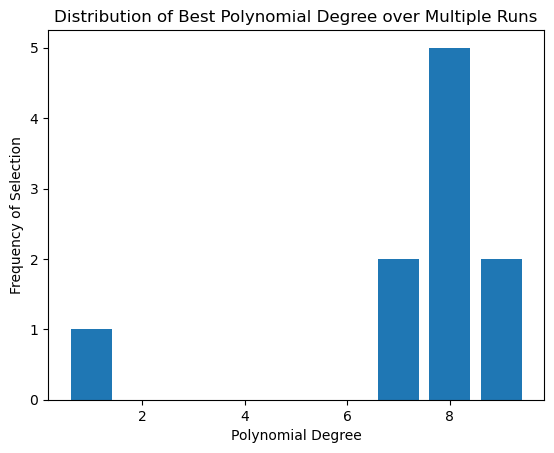

In [14]:
degree_counts = {degree: 0 for degree in range(1,10)}

for run in range(10):
    model, degree, rmse = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, degrees=range(1, 10))
    
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 features
Best Degree: 4, RMSE: 1.2430631979755729, Features: 329
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 features
Best Degree: 5, RMSE: 1.2353699340748265, Features: 791
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 features
Best Degree: 4, RMSE: 1.2424730182245818, Features: 329
Degree 1: 7 features
Degree 2: 35 features
Degree 3: 119 features
Degree 4: 329 features
Degree 5: 791 features
Degree 6: 1715 features
Degree 7: 3431 features
Degree 8: 6434 features
Degree 9: 11439 featu

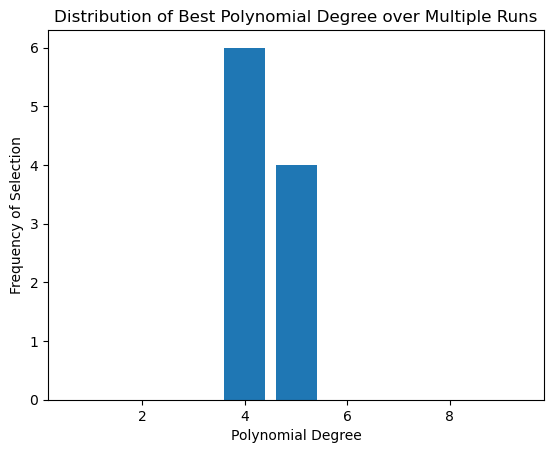

In [15]:
degree_counts = {degree: 0 for degree in range(1,10)}

for run in range(10):
    model, rmse, degree = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, regressor = RidgeCV())
    
    # Track the best degree for this run
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

## Task 2.2 Evaluation

### Evaluate your new nonlinear model against your baseline. Compare RMSE and the y-y hat plots. 

8 was the best performing degree of polynomial in linear regression. But given the size of the training data used to train the model, there is not enough memory to fit it to a 8th degree polynomial regression. The best we could do is degree 7, which as shown by the histogram above, is one of the contenders for best model.

In [41]:
degree=7

polyreg = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('polynomialfeatures',
                 PolynomialFeatures(degree=7, include_bias=False)),
                ('linearregression', LinearRegression())])

Plot y-y hat in validation set and present RMSE

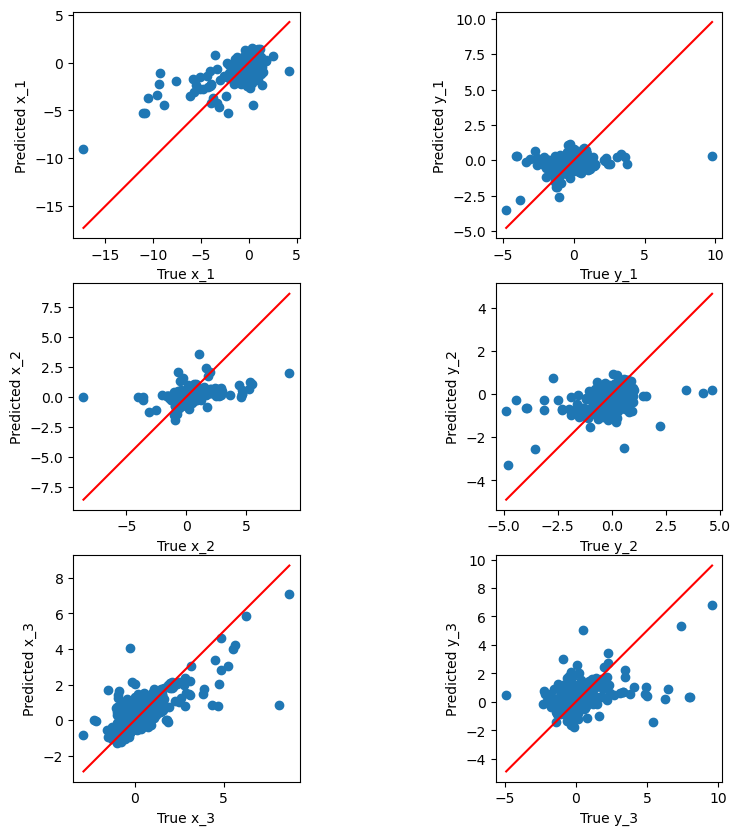

Validation RMSE: 1.1488290320088677


In [42]:
y_dev_pred = polyreg.predict(X_dev_df)

plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = np.sqrt(mean_squared_error(y_dev_df, y_dev_pred))

print(f"Validation RMSE: {rmse}")

RMSE in the test set

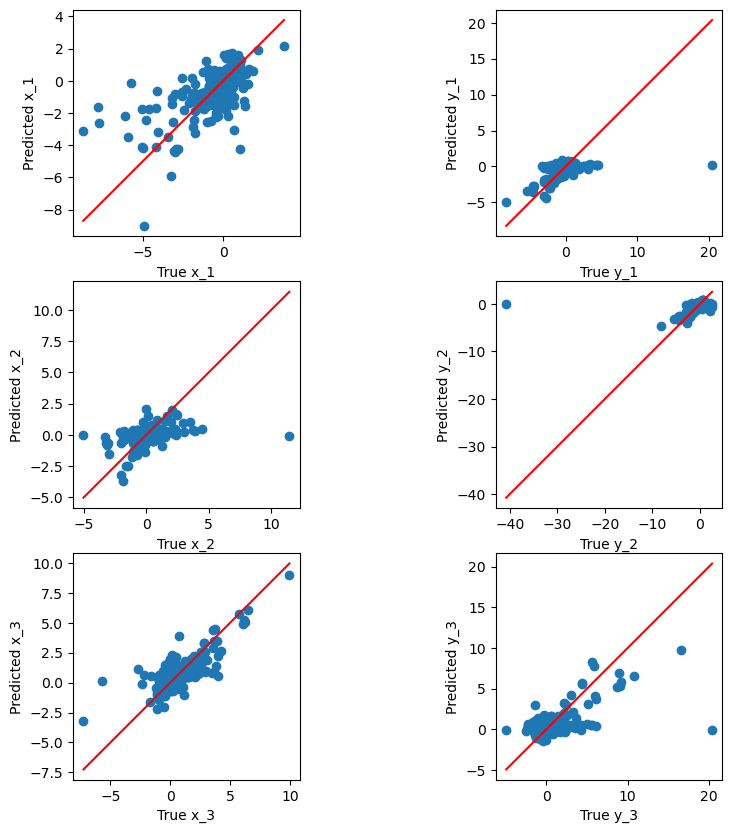

Test RMSE: 1.2723025826483476


In [43]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = np.sqrt(mean_squared_error(y_test_df, y_test_pred))

print(f"Test RMSE: {rmse}")

Regarding the polynomial model for submission of task 2.2

In [32]:
y_polynomial_pred = polyreg.predict(X_kaggle_df)

prediction_to_submission(y_polynomial_pred, '../submissions/polynomial_submission.csv')

Try out RidgeCV and the best degree was 4

In [33]:
degree=3

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

RMSE in validation set for RidgeCV

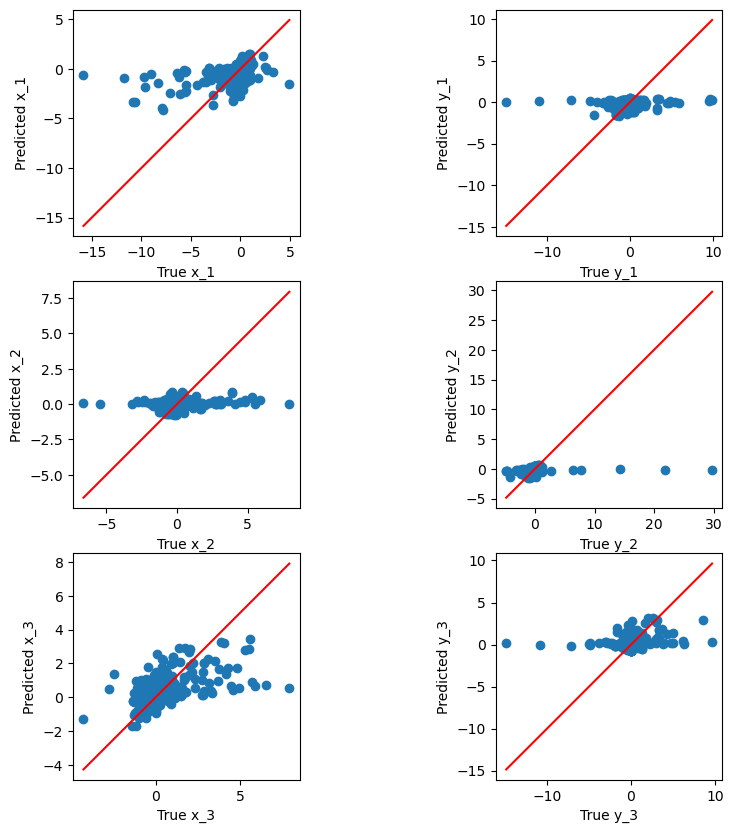

Validation RMSE: 1.2734341861192824


In [31]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

# Calculate RMSE for the validation set
rmse = np.sqrt(mean_squared_error(y_dev_df, y_dev_pred))

print(f"Validation RMSE: {rmse}")

RMSE in test set for RidgeCV

In [32]:
# Predict the targets for the test set
y_test_pred = polyreg.predict(X_test_df)

# Calculate RMSE for the test set
rmse = np.sqrt(mean_squared_error(y_test_df, y_test_pred))

print(f"Test RMSE: {rmse}")

Test RMSE: 1.3911782087563047
